## Setup — import libraries and find the shared data folder

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find the shared data folder from the repository root or app/L8.
def data_path(filename):
    for folder in [Path.cwd(), *Path.cwd().parents]:
        file = folder / "data" / filename
        if file.is_file():
            return file
    raise FileNotFoundError(f"Cannot find {filename} from {Path.cwd()}")

## 1. Load and inspect the data

Each row represents one country in one year. `lifeExp` is life expectancy in years; `gdpPercap` is GDP per person.

In [2]:
df = pd.read_csv(data_path("gapminder.csv"))
print("Rows:", len(df))
print("Countries:", df["country"].nunique())
display(df.head())

Rows: 1704
Countries: 142


,country,continent,year,lifeExp,pop,gdpPercap
0,Afghanistan,Asia,1952,28.801,8425333,779.445314
1,Afghanistan,Asia,1957,30.332,9240934,820.853030
2,Afghanistan,Asia,1962,31.997,10267083,853.100710
3,Afghanistan,Asia,1967,34.020,11537966,836.197138
4,Afghanistan,Asia,1972,36.088,13079460,739.981106


## 2. Line chart — life expectancy over time

Compare **Germany**, **India** and **Kenya**. A line plot is useful when the horizontal axis represents time.

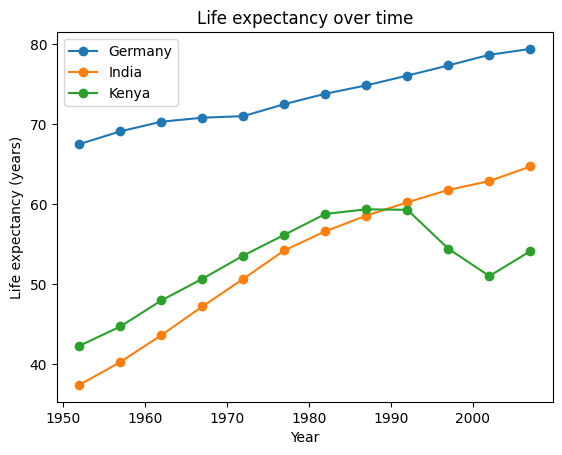

In [3]:
for country in ["Germany", "India", "Kenya"]:
    rows = df[df["country"] == country]
    plt.plot(rows["year"], rows["lifeExp"], marker="o", label=country)
plt.title("Life expectancy over time")
plt.xlabel("Year")
plt.ylabel("Life expectancy (years)")
plt.legend()
plt.show()

## 3. Bar chart — compare continents in 2007

Use the **median country life expectancy** within each continent. This is not a population-weighted figure.

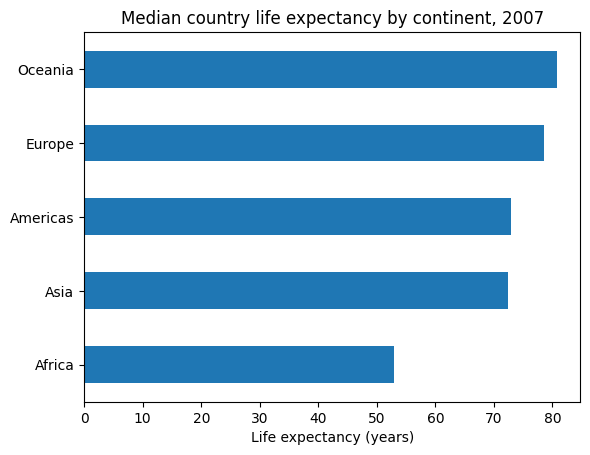

In [4]:
latest = df[df["year"] == 2007]
medians = latest.groupby("continent")["lifeExp"].median().sort_values()
medians.plot(kind="barh")
plt.title("Median country life expectancy by continent, 2007")
plt.xlabel("Life expectancy (years)")
plt.ylabel("")
plt.show()

## 4. Scatter plot — income and life expectancy

A logarithmic x-axis helps display countries with very different income levels. The chart shows association, not causation.

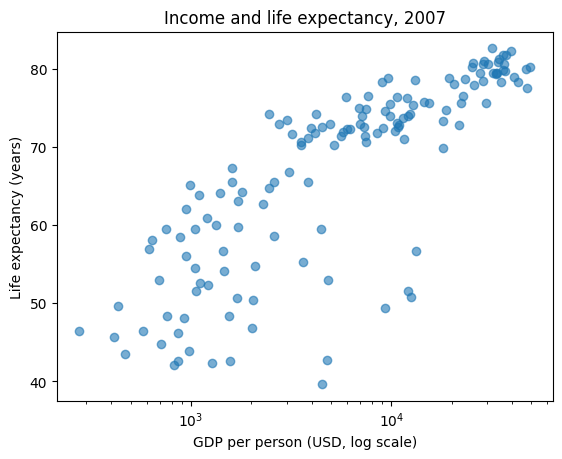

In [5]:
plt.scatter(latest["gdpPercap"], latest["lifeExp"], alpha=0.6)
plt.xscale("log")
plt.title("Income and life expectancy, 2007")
plt.xlabel("GDP per person (USD, log scale)")
plt.ylabel("Life expectancy (years)")
plt.show()

## 5. Histogram — how are countries distributed?

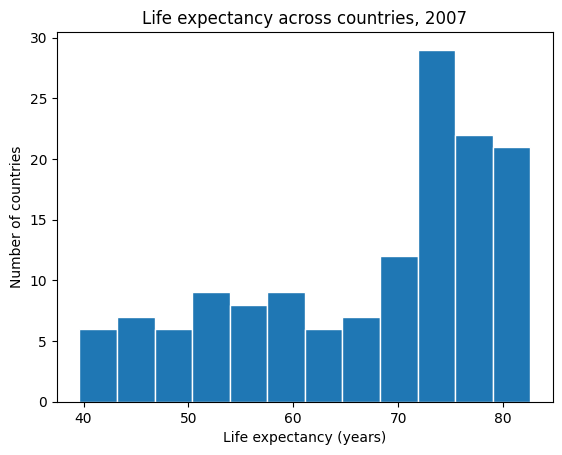

In [6]:
plt.hist(latest["lifeExp"], bins=12, edgecolor="white")
plt.title("Life expectancy across countries, 2007")
plt.xlabel("Life expectancy (years)")
plt.ylabel("Number of countries")
plt.show()

## 6. Box plot — compare distributions by continent

The centre line is the median. The box shows the middle 50% of values.

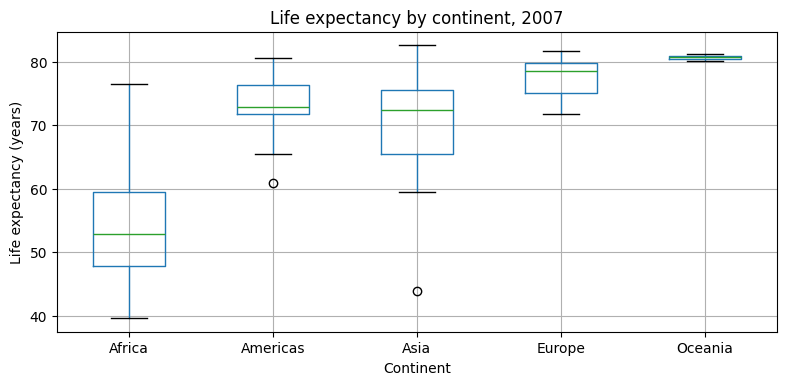

In [7]:
latest.boxplot(column="lifeExp", by="continent", figsize=(9, 4))
plt.title("Life expectancy by continent, 2007")
plt.suptitle("")
plt.xlabel("Continent")
plt.ylabel("Life expectancy (years)")
plt.show()

## 7. Optional: pie chart — a share of the whole

A pie chart is reasonable for a **small number of categories** that sum to a whole. Here we show the population share represented by each continent in the dataset.

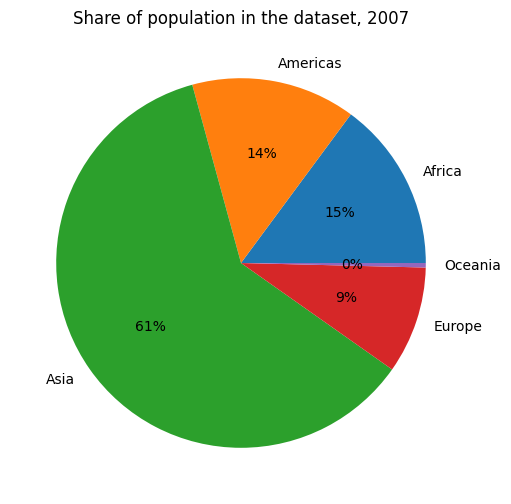

In [8]:
population = latest.groupby("continent")["pop"].sum()
population.plot.pie(autopct="%1.0f%%", ylabel="", figsize=(6, 6))
plt.title("Share of population in the dataset, 2007")
plt.show()

### Discuss

Why might a bar chart be easier to compare than a pie chart? Why should we not interpret the scatter plot as proof that income causes longer life expectancy?

## Your turn — short challenges

1. Replace **Kenya** with **Japan** in the line chart.
2. Change the histogram to `bins=8`.
3. Explain which chart best compares continents.

In [9]:
# Write your solution here.
# Start by changing one line from an example above.